In [ ]:
from classes.ACER_data_handler import ACERDataModule

data_module = ACERDataModule(
    # ACER_csv_path="./Data/ACER_2000-2024.csv",
    n_lookback_days=1,
    horizon=1,
    start_padding_days=2,
    end_padding_days=0,
    norm_by_dayly_deviation=True,
    sample_hour=16,
    val_split=[2017,2024],
    normalize_volume=False,
    scaling_mode_robust=True,
    normalize_temperature=True,
    return_fields =[
                f"concat[input_temperature_lagged_view[-1,{1},24], input_volume_lagged_view[-1,{1},1]]",
                "input_temperature_forecast",
                "target_volume",
                "volume_journalier_moyen"
            ],
)
data_module.get_ready()

In [2]:
print(f"Nb samples: {data_module.length}")
print(f"Nb samples train: {len(data_module._train_idx)}")
print(f"Nb samples val: {len(data_module._val_idx)}")

Nb samples: 2098
Nb samples train: 1687
Nb samples val: 411


In [59]:
acerDF = data_module.ACER_df
allDf = data_module.allData_df

In [67]:
# analyse_c = acerDF['volume_norm']
analyse_c = allDf['T0_volume_mod']
#Fill NaN values with 0
analyse_c = analyse_c.fillna(0)

#Premier quartile des volumes journaliers moyens
Q1 = analyse_c.quantile(0.25)
#Médiane des volumes journaliers moyens
Q2 = analyse_c.median()
#Troisième quartile des volumes journaliers moyens
Q3 = analyse_c.quantile(0.75)

#Pourcentage valeur sous 1
nb_sous_1 = (analyse_c <= 1).sum()
pourcentage_sous_1 = nb_sous_1 / len(analyse_c) * 100
#Pourcentage nulles ou 0
pourcentage_nulles_0 = (analyse_c == 0).sum() / len(analyse_c) * 100


print(f"Premier quartile des volumes journaliers moyens: {Q1}")
print(f"Médiane des volumes journaliers moyens: {Q2}")
print(f"Troisième quartile des volumes journaliers moyens: {Q3}")
print(f"Nombre de valeurs sous 1: {nb_sous_1}")
print(f"Pourcentage de valeurs sous 1: {pourcentage_sous_1}%")
print(f"Pourcentage de valeurs nulles ou 0: {pourcentage_nulles_0}%")


Premier quartile des volumes journaliers moyens: 0.02840941962863125
Médiane des volumes journaliers moyens: 0.6798896096471634
Troisième quartile des volumes journaliers moyens: 1.2737040122737677
Nombre de valeurs sous 1: 1358
Pourcentage de valeurs sous 1: 64.72831267874166%
Pourcentage de valeurs nulles ou 0: 24.40419447092469%


In [66]:
stats = (
    data_module.allData_df
    .assign(year=data_module.allData_df.index.get_level_values('date').year)
    .groupby(['year', 'system'])["volume entaille"]  # Group by BOTH year and system
    .agg([
        ('Nombre de jours', 'count'),
        ('Volume total', 'sum'),
        ('Volume moyen', 'mean'),
        # ('Volume premier quartile', lambda x: x.quantile(0.25)),
        # ('Volume médian', 'median'),
        # ('Volume troisième quartile', lambda x: x.quantile(0.75)),
        ('Volume écart-type', 'std'),
        # ('Volume min', 'min'),
        ('Volume max', 'max'),
        ('% de valeurs nulles', lambda x: (x == 0).sum() / len(x) * 100)
    ])
    .groupby('year')  # Average across systems
    .mean()
    .T
)

# Add row for number of systems per year
num_systems = (
    data_module.allData_df
    .groupby(data_module.allData_df.index.get_level_values('date').year)
    .apply(lambda x: x.index.get_level_values('system').nunique())  # Extract 'system' from index
)

stats.loc['Nombre de systèmes'] = num_systems
stats = stats.T

stats_copy = stats.copy()

# Add average row
stats.loc['Moyenne sur toutes les années'] = stats_copy.mean(axis=0)
stats.loc['Médiane sur toutes les années'] = stats_copy.median(axis=0)
stats.loc['Écart-type sur toutes les années'] = stats_copy.std(axis=0)
stats.loc['Maximum sur toutes les années'] = stats_copy.max(axis=0)
stats.loc['Minimum sur toutes les années'] = stats_copy.min(axis=0)
stats.loc['Somme sur toutes les années'] = stats_copy.sum(axis=0)

stats.style


,Nombre de jours,Volume total,Volume moyen,Volume écart-type,Volume max,% de valeurs nulles,Nombre de systèmes
year,,,,,,,
2000,39.000000,74.712785,1.915712,1.648928,7.340976,20.512821,1.000000
2001,45.000000,97.055556,2.156790,1.947307,6.411111,24.444444,1.000000
2005,35.000000,49.892100,1.425489,1.242127,5.075145,11.428571,1.000000
2006,35.000000,71.320236,2.037721,1.663518,5.950884,25.714286,1.000000
2007,41.000000,62.004728,1.512310,1.189083,4.130024,21.951220,1.000000
2009,46.000000,93.309210,2.028461,3.556802,19.125382,36.956522,1.000000
2010,36.000000,108.213820,3.005939,1.957802,6.727063,13.888889,2.000000
2011,25.000000,31.660224,1.266409,1.454248,4.380085,41.333333,3.000000
2012,36.000000,83.562952,2.321193,1.654746,5.545892,16.666667,4.000000


# Prédiction naive

In [3]:
import torch
from models.training import RegressionMetrics

def target_statistics(y_true):
    mean_val = y_true.mean().item()
    median_val = y_true.median().item()
    max_val = y_true.max().item()
    zero_ratio = (y_true == 0).float().mean().item()

    print("\n--- TARGET DISTRIBUTION ---")
    print(f"Mean:   {mean_val:.4f}")
    print(f"Median: {median_val:.4f}")
    print(f"Max:    {max_val:.4f}")
    print(f"% Zeros: {100*zero_ratio:.2f}%")

    return mean_val

def baseline_wape(y_true, prediction_value=None):
    if prediction_value is None:
        mean_val = y_true.mean()
        baseline_pred = torch.full_like(y_true, mean_val)
    else:
        baseline_pred = torch.full_like(y_true, prediction_value)

    sae = torch.abs(baseline_pred - y_true).sum()
    sum_y = y_true.sum()

    wape = 100 * sae / (sum_y + 1e-12)

    print("--- BASELINE (predict mean) ---")
    print(f"Baseline WAPE: {wape.item():.2f}%")

    print("--- BASELINE METRICS ---")
    reg_metrics = RegressionMetrics("cpu")
    reg_metrics.update(baseline_pred, y_true)
    metrics = reg_metrics.compute()
    for metric_name, metric_value in metrics.items():
        print(f"{metric_name}: {metric_value:.4f}")

    return wape.item()

In [4]:
from classes.ACER_data_handler import ACERDataModule

_data_module = ACERDataModule(
    n_lookback_days=3,
    horizon=1,
    start_padding_days=2,
    end_padding_days=0,
    norm_by_dayly_deviation=False,
    sample_hour=23,
    val_split=[2017, 2024],
    normalize_volume=False,
    normalize_temperature=False,
    scaling_mode_robust=True,
    scaling_per_feature=False,
    return_fields=[
        f"concat[input_temperature_lagged_view[-1,{3},24], input_volume_lagged_view[-1,{3},1]]",
        "input_temperature_forecast",
        "target_volume",
        "volume_journalier_moyen",
    ]
)
_data_module.get_ready()

# TRAIN DATASET ANALYSIS
train_true_y_tensor = _data_module.get_tensor("target_volume", idx=_data_module._train_idx)
print("*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*")
print("Statistiques pour le jeu d'entraînement:")
mean_train = target_statistics(train_true_y_tensor)
baseline_wape_value = baseline_wape(train_true_y_tensor)
print("Std:", train_true_y_tensor.std().item())

# VALIDATION DATASET ANALYSIS
val_true_y_tensor = _data_module.get_tensor("target_volume", idx=_data_module._val_idx)
print("\n*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*")
print("Statistiques pour le jeu de validation:")
mean_val = target_statistics(val_true_y_tensor)
baseline_wape_value = baseline_wape(val_true_y_tensor)
print("Std:", val_true_y_tensor.std().item())
print("\nResultats avec la moyenne du jeu d'entraînement comme prédiction pour le jeu de validation.")
_ = baseline_wape(val_true_y_tensor, prediction_value=mean_train)

*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*
Statistiques pour le jeu d'entraînement:

--- TARGET DISTRIBUTION ---
Mean:   2.5482
Median: 2.1651
Max:    19.1254
% Zeros: 23.47%
--- BASELINE (predict mean) ---
Baseline WAPE: 76.83%
--- BASELINE METRICS ---
MSE: 5.8869
RMSE: 2.4263
WAPE: 76.8300
RMSE%: 95.2174
R2: -0.0000
Std: 2.4270081938196024

*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*
Statistiques pour le jeu de validation:

--- TARGET DISTRIBUTION ---
Mean:   2.8821
Median: 2.6968
Max:    10.5286
% Zeros: 28.22%
--- BASELINE (predict mean) ---
Baseline WAPE: 76.86%
--- BASELINE METRICS ---
MSE: 6.8984
RMSE: 2.6265
WAPE: 76.8628
RMSE%: 91.1295
R2: -0.0000
Std: 2.629688236837805

Resultats avec la moyenne du jeu d'entraînement comme prédiction pour le jeu de validation.
--- BASELINE (predict mean) ---
Baseline WAPE: 76.74%
--- BASELINE METRICS ---
MSE: 7.0100
RMSE: 2.6476
WAPE: 76.7418
RMSE%: 91.8633
R2: -0.0162


# Courbe des Volumes

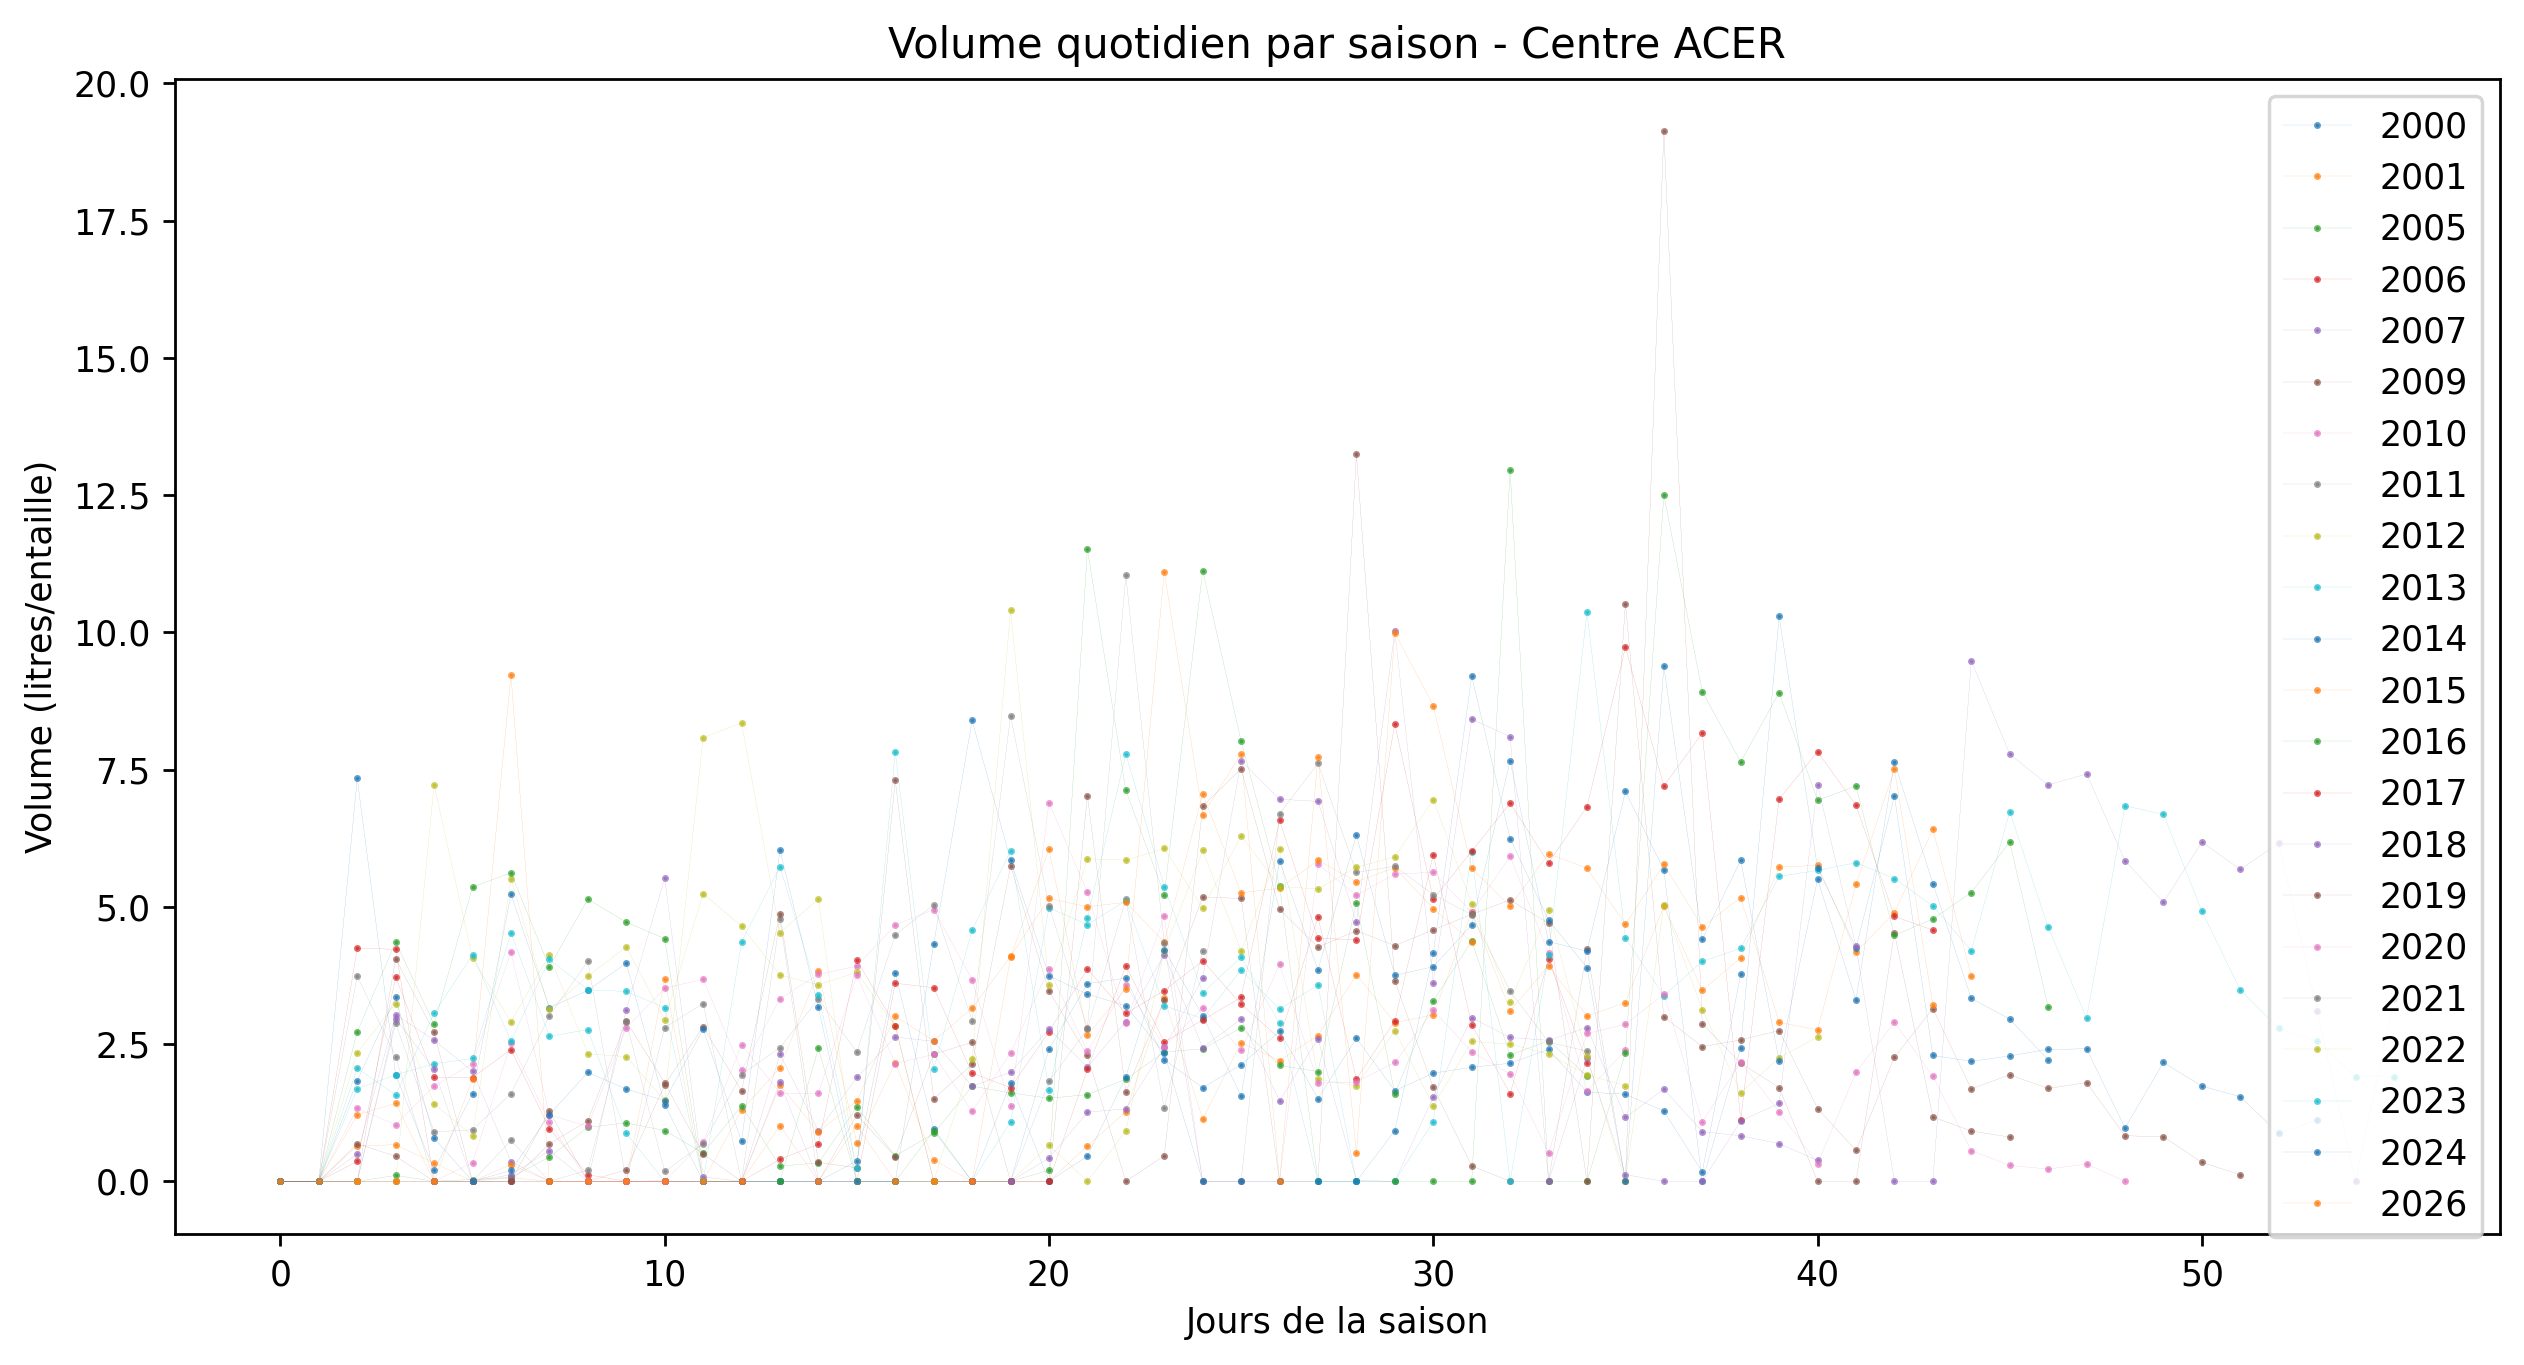

In [5]:
import matplotlib.pyplot as plt
#Un seul graphique qui montre toutes les années, avec des couleurs différentes pour chaque année.
fig, ax = plt.subplots(figsize=(12, 6), dpi=250)
for year in data_module.get_years():
    year_dataset = data_module.get_first_system_for_years([year])
    year_dataset.ensure_precached("cpu")

    year_volume = year_dataset._resolve_field("target_volume")
    volume_journalier_moyen = year_dataset._resolve_field("volume_journalier_moyen")

    y = year_dataset.inverse_normalize_volume(year_volume)
    if data_module.norm_by_dayly_deviation:
        y = y * volume_journalier_moyen

    progrssive_sum = y.cumsum(dim=0)

    ax.plot(y, label=f"{year}", linewidth=0.05, alpha=0.7, marker='o', markersize=1)

ax.set_xlabel("Jours de la saison")
ax.set_ylabel("Volume (litres/entaille)")
ax.set_title("Volume quotidien par saison - Centre ACER")
ax.legend()

plt.show()

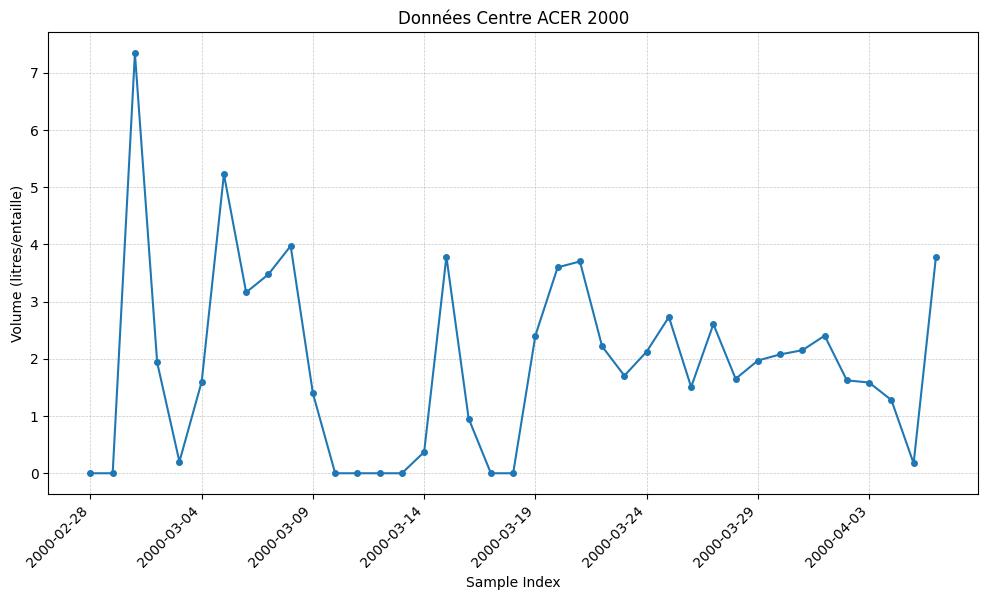

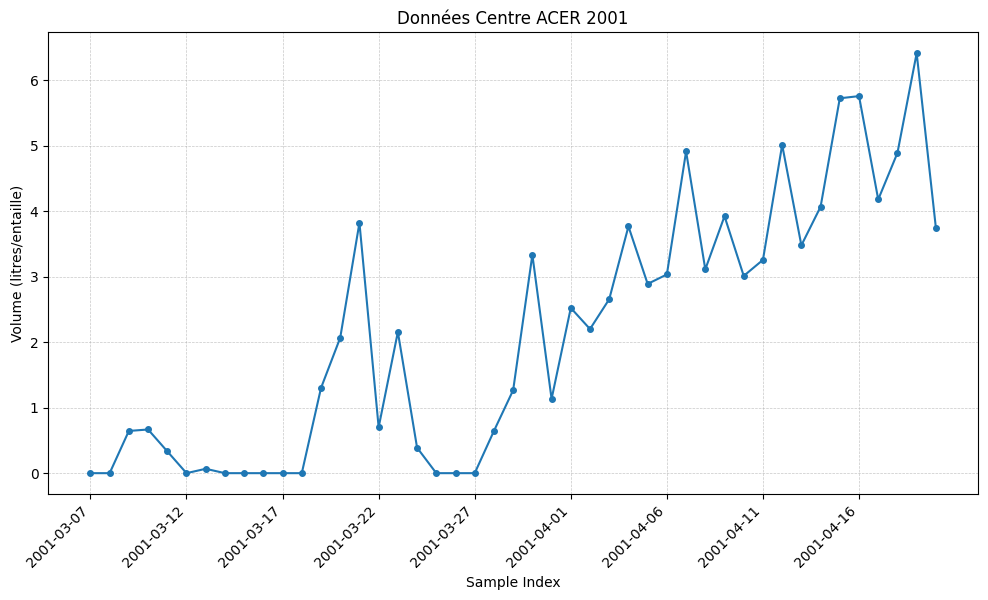

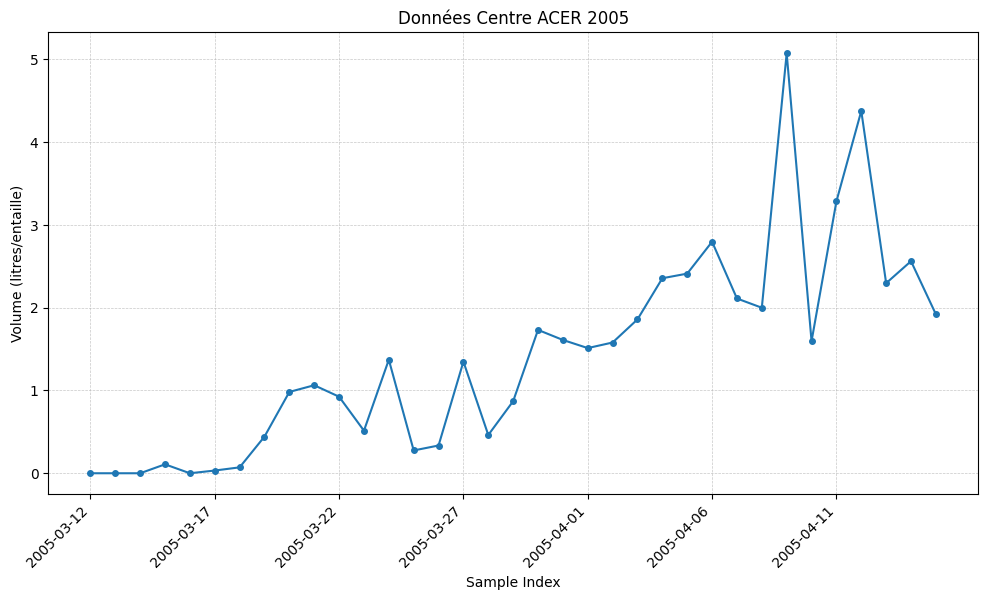

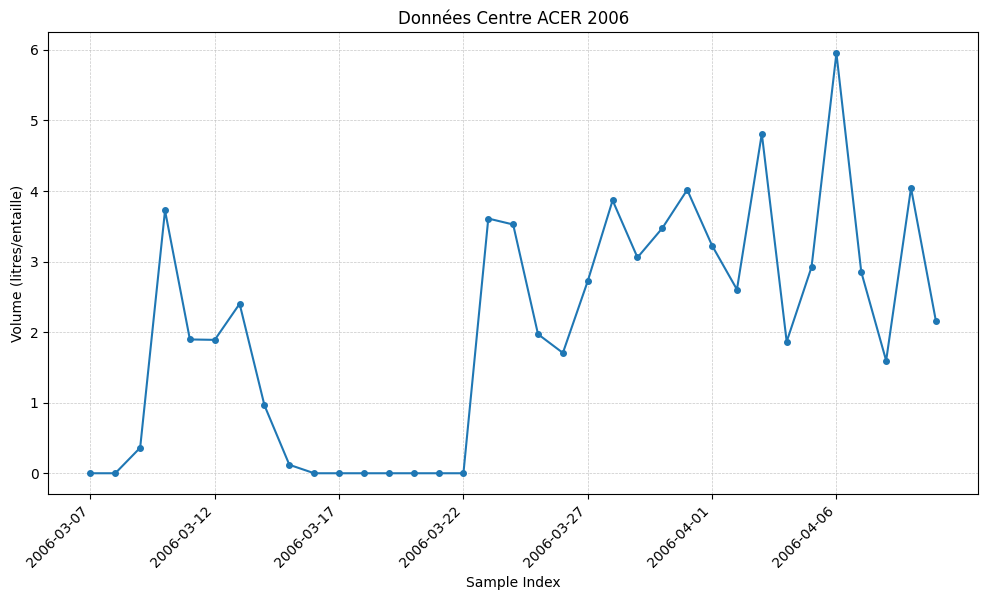

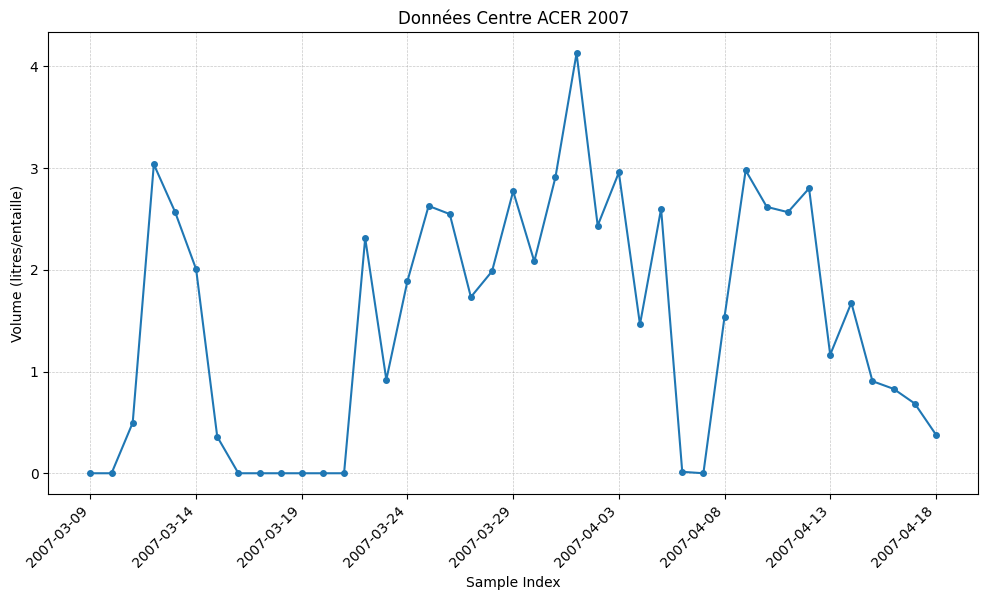

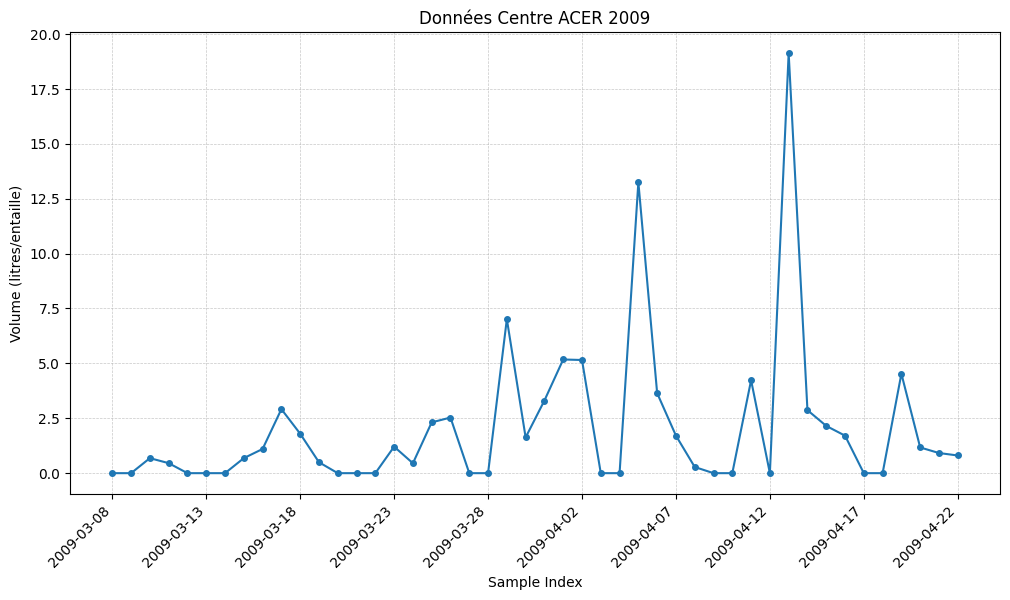

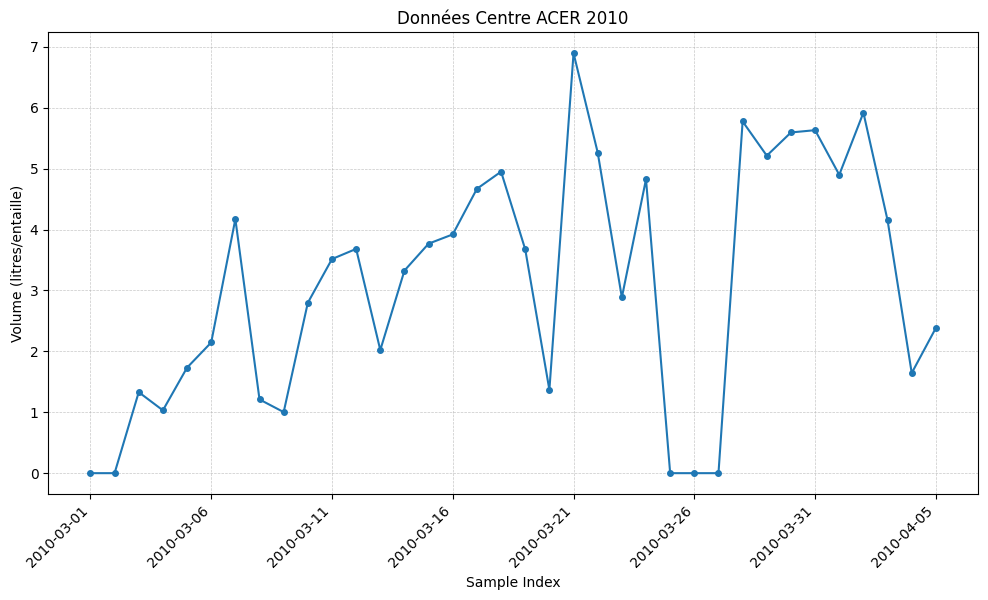

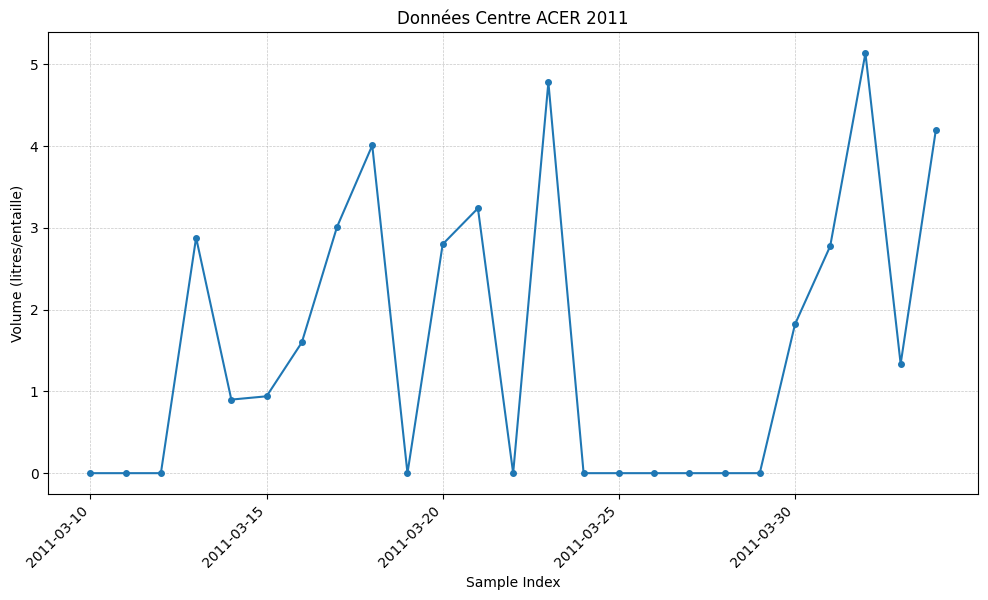

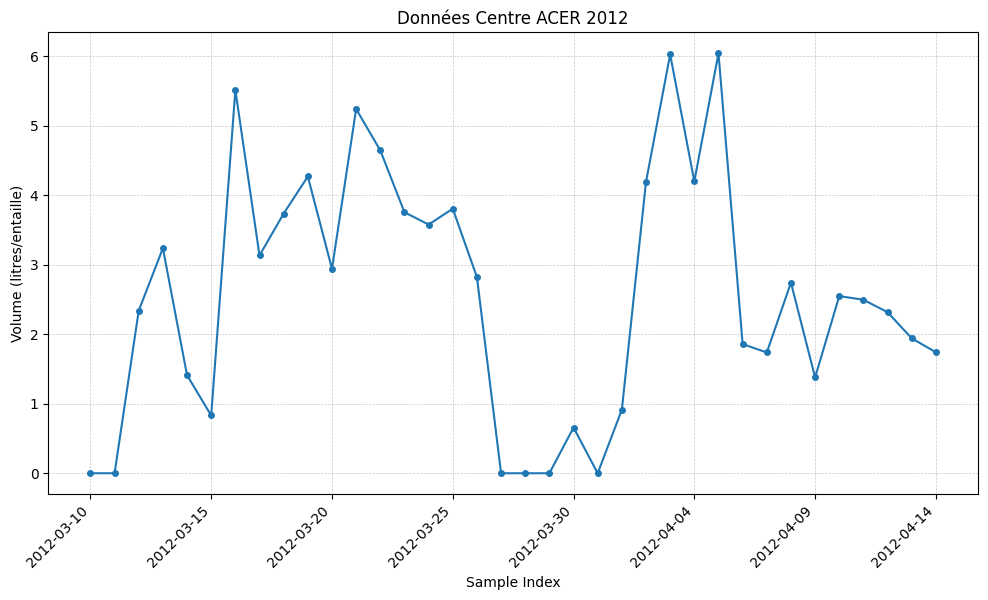

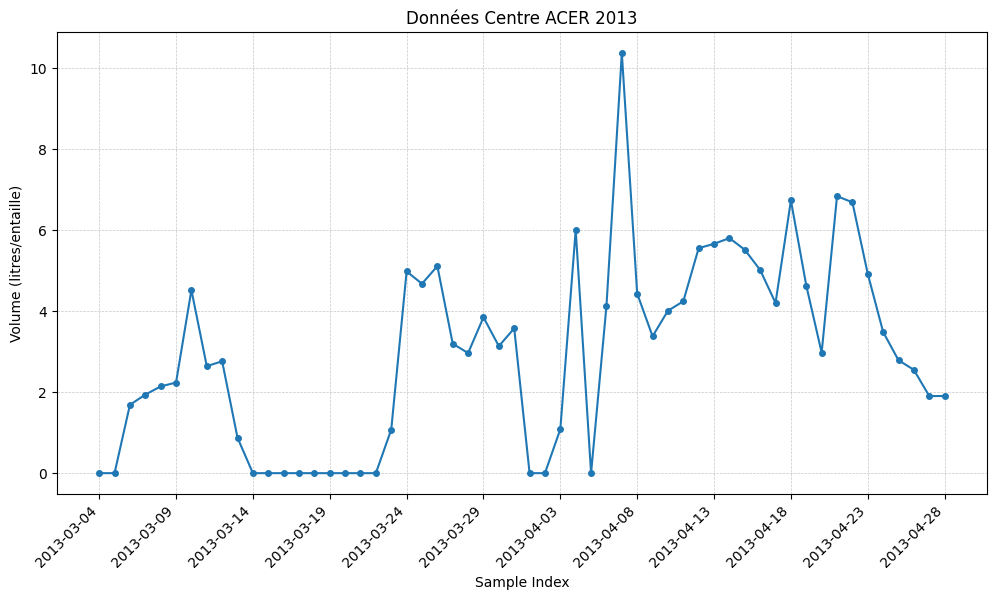

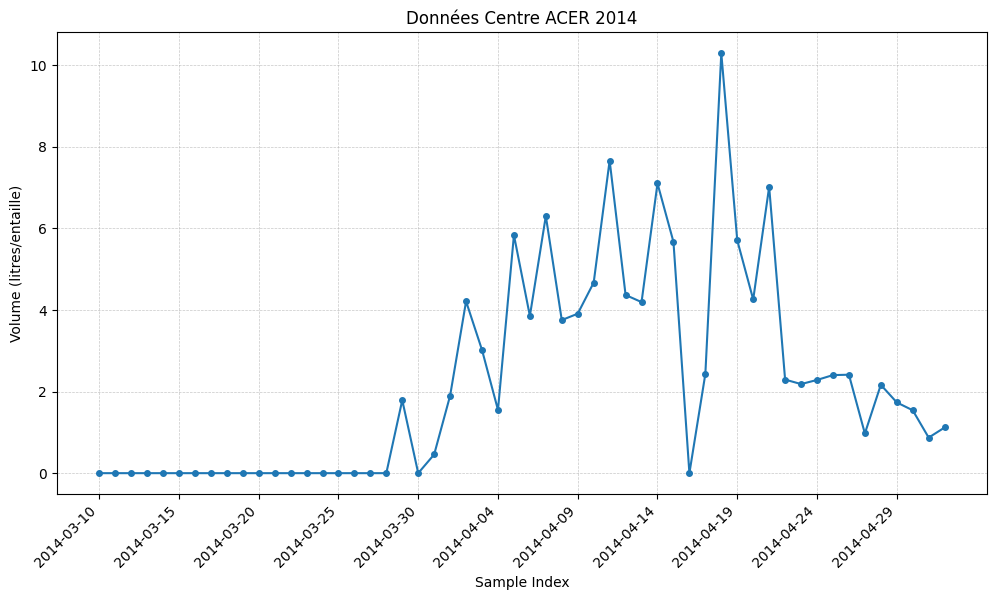

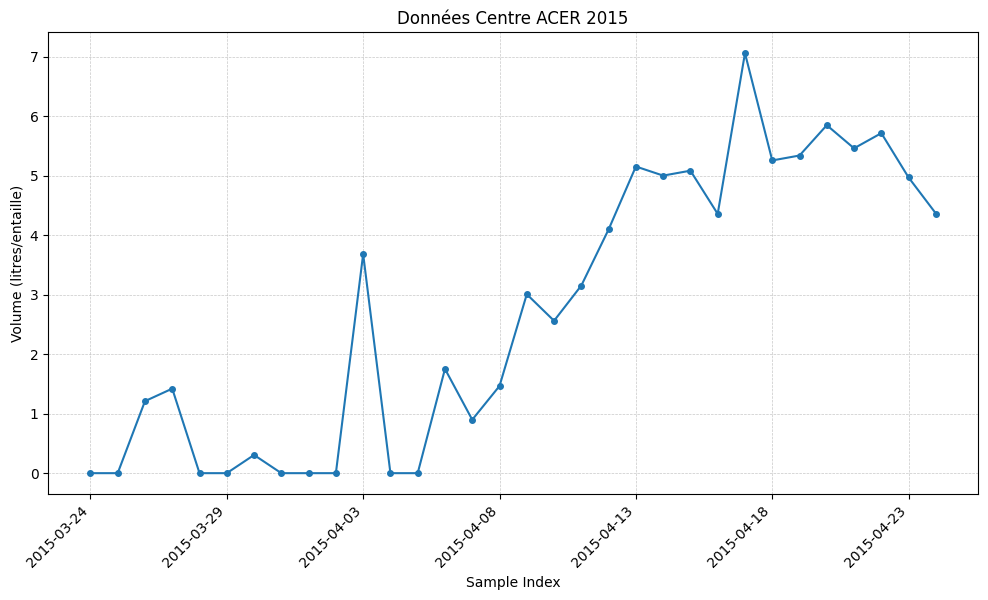

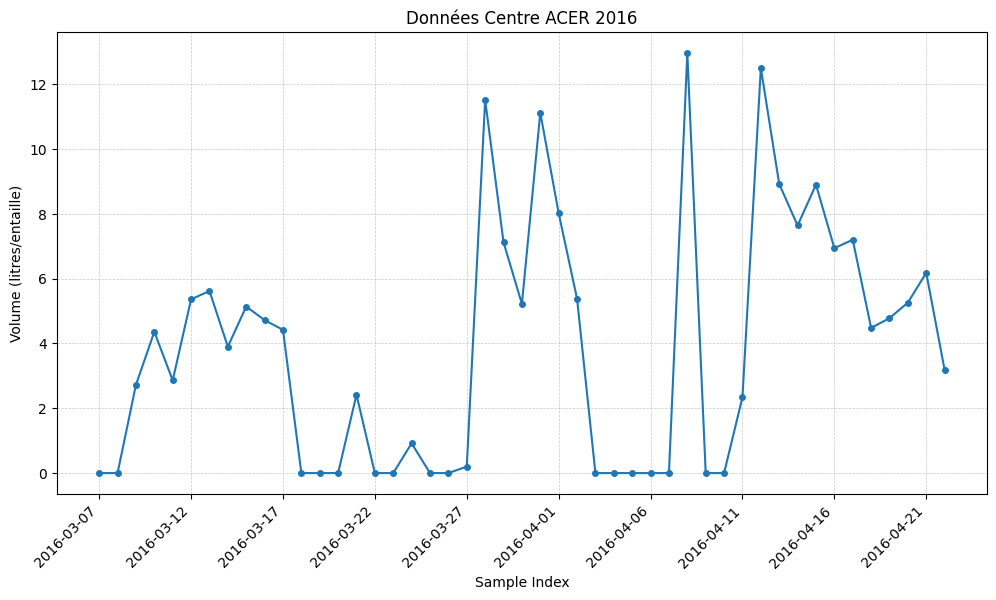

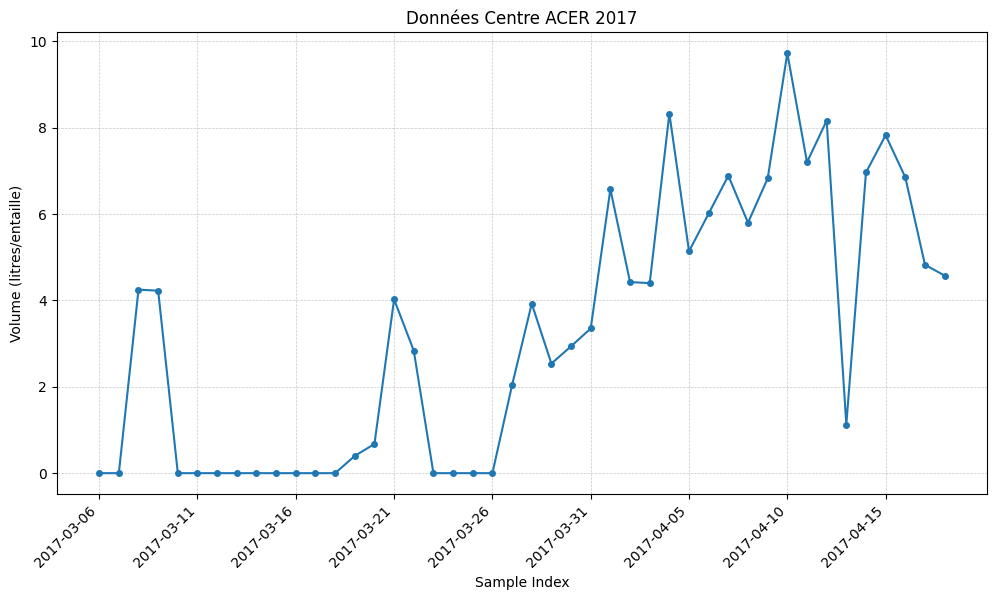

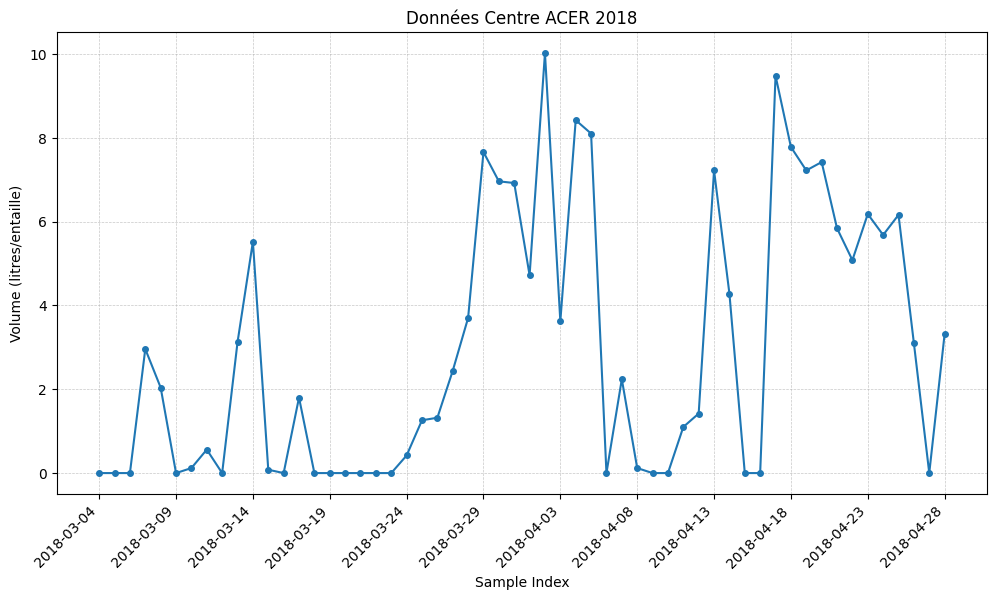

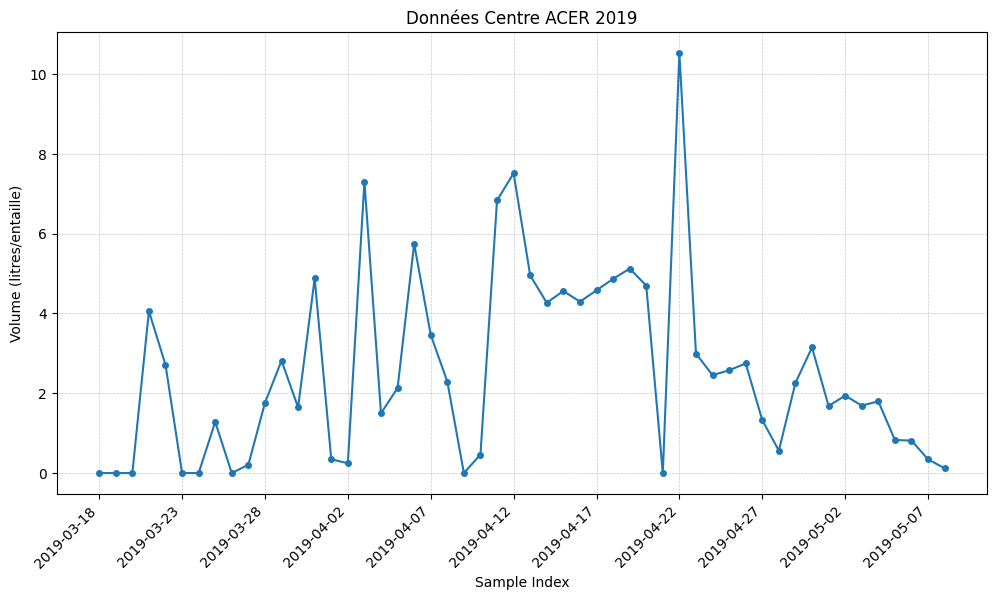

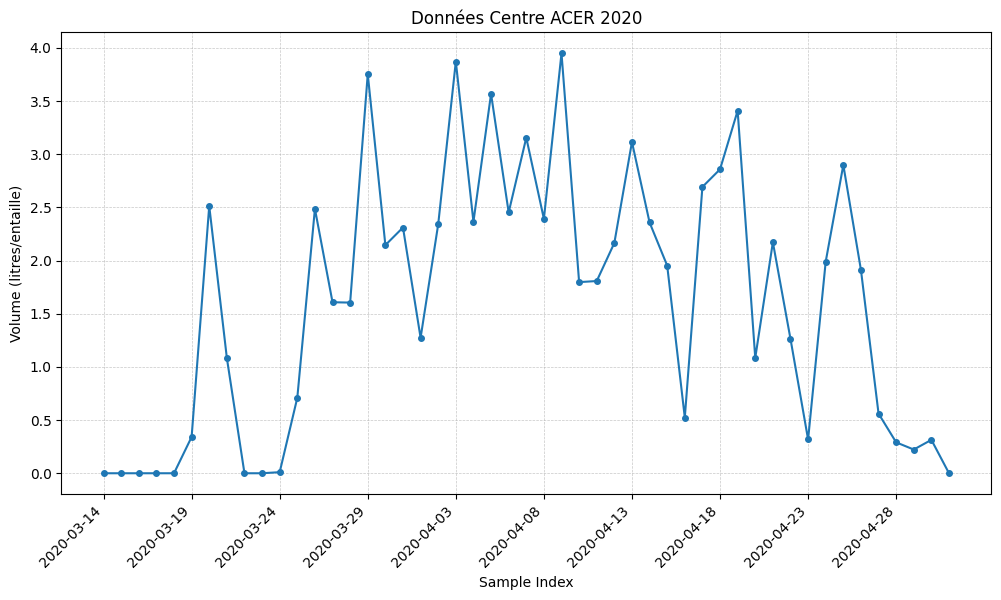

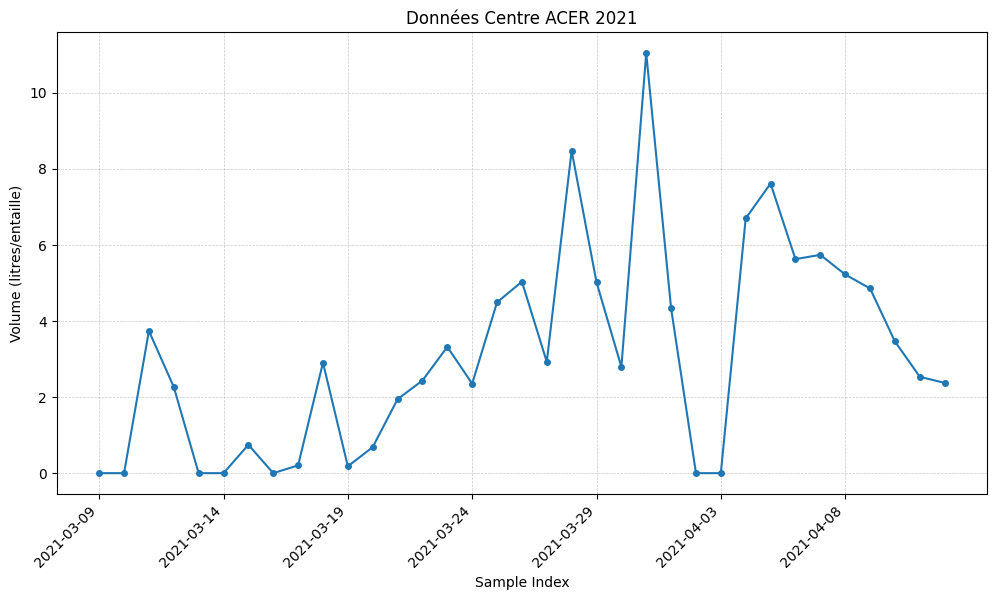

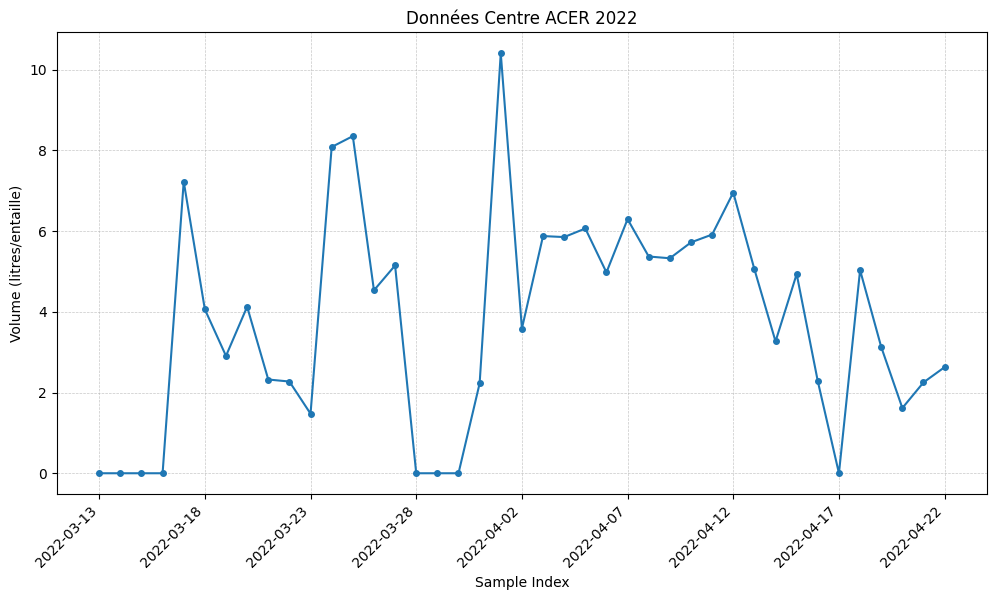

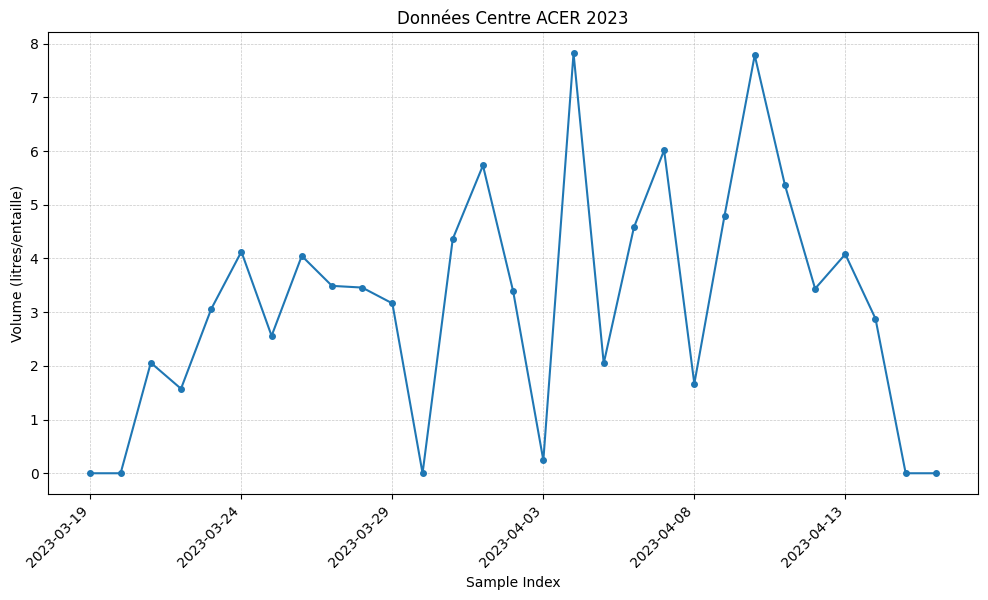

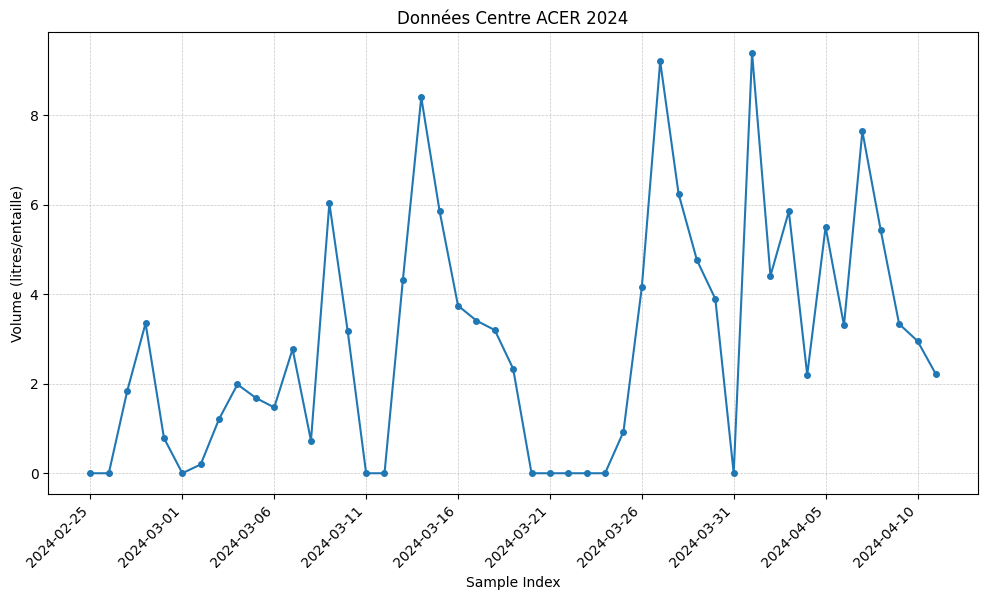

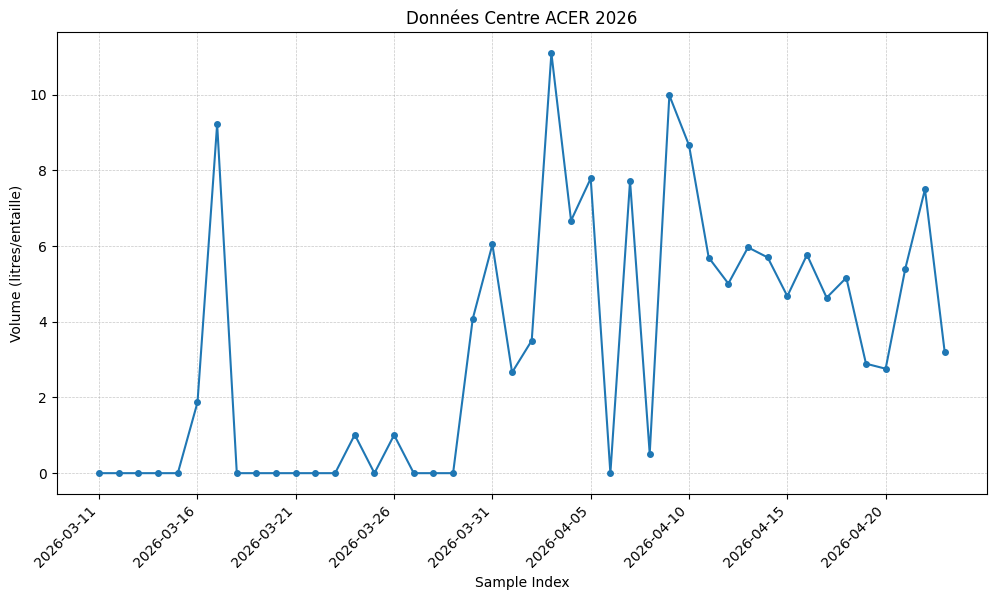

In [6]:
for year in data_module.get_years():
    year_dataset = data_module.get_first_system_for_years([year])
    year_dataset.ensure_precached("cpu")

    test = year_dataset._resolve_field("target_volume")
    volume_journalier_moyen = year_dataset._resolve_field("volume_journalier_moyen")

    y = year_dataset.inverse_normalize_volume(test)
    if data_module.norm_by_dayly_deviation:
        y = y * volume_journalier_moyen

    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(y, marker='o', markersize=4)

    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Volume (litres/entaille)")
    ax.set_title(f"Données Centre ACER {year}")
    # ax.legend(
    #     loc="upper left",
    #     bbox_to_anchor=(1.05, 1.0),  # same x, higher y
    #     borderaxespad=0
    # )

    showDates = 5  # Show date every 30 days
    if showDates > 0:
        id_date_sys = year_dataset._resolve_field("id_date_system")
        dates = id_date_sys[:, 0]
        ax.set_xticks(range(0, len(dates), showDates))
        ax.set_xticklabels(
            [str(d)[:10] for d in dates[::showDates]],
            rotation=45,
            ha="right",
        )

    #Montrer la grille
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

    plt.show()


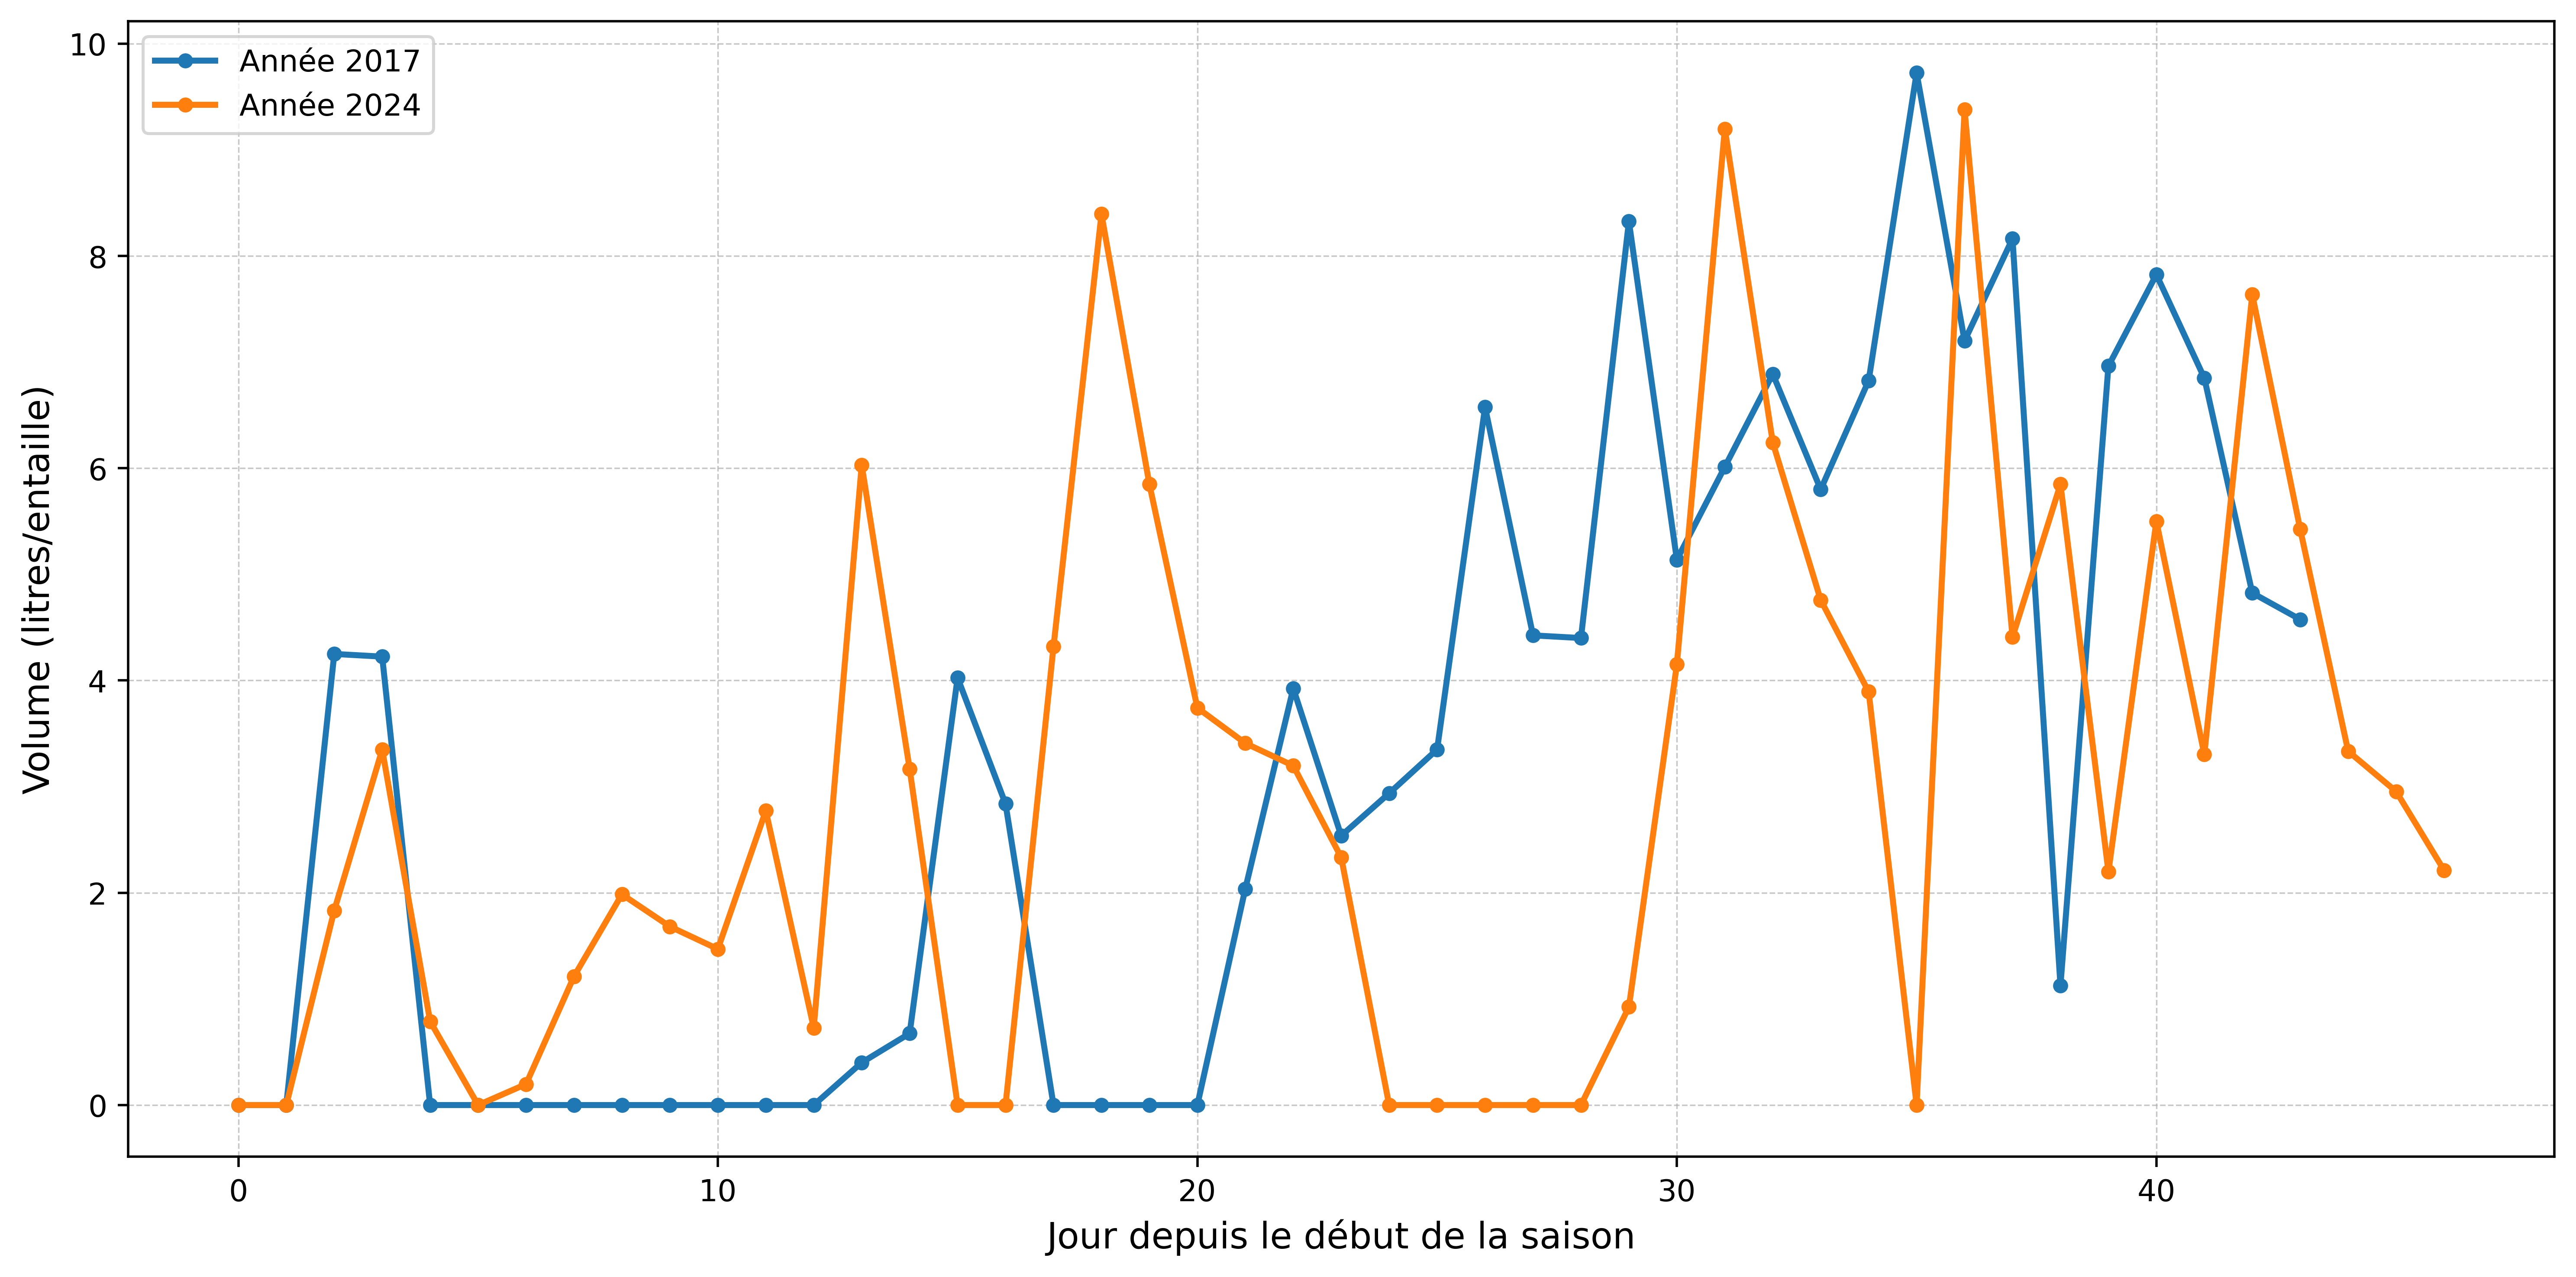

In [25]:
import matplotlib.pyplot as plt

# Créer une figure une seule fois
fig, ax = plt.subplots(figsize=(12, 6), dpi=500)

# Récupérer les années disponibles et en sélectionner 3
years = data_module.get_years()
selected_years = [2017, 2024]

# Dictionnaire pour stocker les données
all_data = {}

for year in selected_years:
    year_dataset = data_module.get_first_system_for_years([year])
    year_dataset.ensure_precached("cpu")

    test = year_dataset._resolve_field("target_volume")
    volume_journalier_moyen = year_dataset._resolve_field("volume_journalier_moyen")

    y = year_dataset.inverse_normalize_volume(test)
    if data_module.norm_by_dayly_deviation:
        y = y * volume_journalier_moyen

    all_data[year] = {
        'y': y,
        'id_date_system': year_dataset._resolve_field("id_date_system")
    }
    
    # Ajouter la courbe au graphique
    ax.plot(y, marker='o', markersize=4, label=f"Année {year}", linewidth=2)

# Configuration du graphique
ax.set_xlabel("Jour depuis le début de la saison", fontsize=12)
ax.set_ylabel("Volume (litres/entaille)", fontsize=12)
# ax.set_title(f"Données Centre ACER - 2017 et 2024", fontsize=14)
ax.legend(loc="upper left", fontsize=10)

# Afficher la grille
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# Afficher les dates (utiliser la première année comme référence)
showDates = 0
if showDates > 0:
    first_year_data = all_data[selected_years[0]]
    id_date_sys = first_year_data['id_date_system']
    dates = id_date_sys[:, 0]
    ax.set_xticks(range(0, len(dates), showDates))
    ax.set_xticklabels(
        [str(d)[:10] for d in dates[::showDates]],
        rotation=45,
        ha="right",
    )

plt.tight_layout()
plt.show()
